# 芒果品种分类 | EfficientNet-B4

## 1. 导入库与训练配置

In [1]:
DATASET_NAME = 'Mango Dataset'
import copy
import csv
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm import tqdm

plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans', 'Arial Unicode MS', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32
NUM_EPOCHS = 100
LEARNING_RATE = 1e-4
PATIENCE = 10
NUM_WORKERS = 0
IMG_SIZE = 224

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == 'train':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / DATASET_NAME
MODEL_DIR = PROJECT_ROOT / 'models'
RUNS_DIR = PROJECT_ROOT / 'train' / 'runs'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Dataset directory not found: {DATA_DIR}')
print(f'Dataset: {DATA_DIR.resolve()}')
print(f'Model output: {MODEL_DIR.resolve()}')
print(f'Run output: {RUNS_DIR.resolve()}')
print(f'Device: {DEVICE}')
print(f'最大训练轮数: {NUM_EPOCHS} | 早停耐心: {PATIENCE}')

Dataset: D:\WorkSpace2\plants-intelligent-system\Mango Dataset
Model output: D:\WorkSpace2\plants-intelligent-system\models
Run output: D:\WorkSpace2\plants-intelligent-system\train\runs
Device: cuda
最大训练轮数: 100 | 早停耐心: 10


## 2. 数据增强与数据加载

## 2.1 数据集初始化

In [2]:
from PIL import Image, ImageFile

# 轻量预处理：统一输入尺寸，并只对训练集施加适度增强。
ImageFile.LOAD_TRUNCATED_IMAGES = True

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

split_dirs = {split: DATA_DIR / split for split in ('train', 'val', 'test')}
missing_splits = [split for split, path in split_dirs.items() if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f'Missing dataset splits: {missing_splits}')

# 提前检查图片完整性，避免坏文件在训练中途才触发异常。
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
invalid_files = []
for split, split_dir in split_dirs.items():
    for image_path in split_dir.rglob('*'):
        if image_path.suffix.lower() in image_extensions:
            try:
                with Image.open(image_path) as image:
                    image.verify()
            except Exception as exc:
                invalid_files.append(f'{split}: {image_path} ({exc})')
if invalid_files:
    raise RuntimeError('发现无法读取的图片，请先修复或删除：\n' + '\n'.join(invalid_files[:10]))

image_datasets = {
    'train': datasets.ImageFolder(split_dirs['train'], train_transform),
    'val': datasets.ImageFolder(split_dirs['val'], eval_transform),
    'test': datasets.ImageFolder(split_dirs['test'], eval_transform),
}
class_names = image_datasets['train'].classes
class_to_idx = image_datasets['train'].class_to_idx
for split, ds in image_datasets.items():
    if ds.class_to_idx != class_to_idx:
        raise ValueError(f'{split} class mapping differs from train: {ds.class_to_idx}')
    if not ds.samples:
        raise ValueError(f'{split} split is empty')

loaders = {
    split: DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=(split == 'train'),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'),
    )
    for split, ds in image_datasets.items()
}
print('Classes:', class_to_idx)
for split, ds in image_datasets.items():
    print(f'{split}: {len(ds)} images')

Classes: {'Anwar Ratool': 0, 'Chaunsa (Black)': 1, 'Chaunsa (Summer Bahisht)': 2, 'Chaunsa (White)': 3, 'Dosehri': 4, 'Fajri': 5, 'Langra': 6, 'Sindhri': 7}
train: 1120 images
val: 320 images
test: 160 images


## 2.2数据集统计

数据集详细统计

【TRAIN】集合:
  Anwar Ratool             :  140 张 (12.50%)
  Chaunsa (Black)          :  140 张 (12.50%)
  Chaunsa (Summer Bahisht) :  140 张 (12.50%)
  Chaunsa (White)          :  140 张 (12.50%)
  Dosehri                  :  140 张 (12.50%)
  Fajri                    :  140 张 (12.50%)
  Langra                   :  140 张 (12.50%)
  Sindhri                  :  140 张 (12.50%)
  总计                       : 1120 张

【VAL】集合:
  Anwar Ratool             :   40 张 (12.50%)
  Chaunsa (Black)          :   40 张 (12.50%)
  Chaunsa (Summer Bahisht) :   40 张 (12.50%)
  Chaunsa (White)          :   40 张 (12.50%)
  Dosehri                  :   40 张 (12.50%)
  Fajri                    :   40 张 (12.50%)
  Langra                   :   40 张 (12.50%)
  Sindhri                  :   40 张 (12.50%)
  总计                       :  320 张

【TEST】集合:
  Anwar Ratool             :   20 张 (12.50%)
  Chaunsa (Black)          :   20 张 (12.50%)
  Chaunsa (Summer Bahisht) :   20 张 (12.50%)
  Chaunsa (White)          :   2

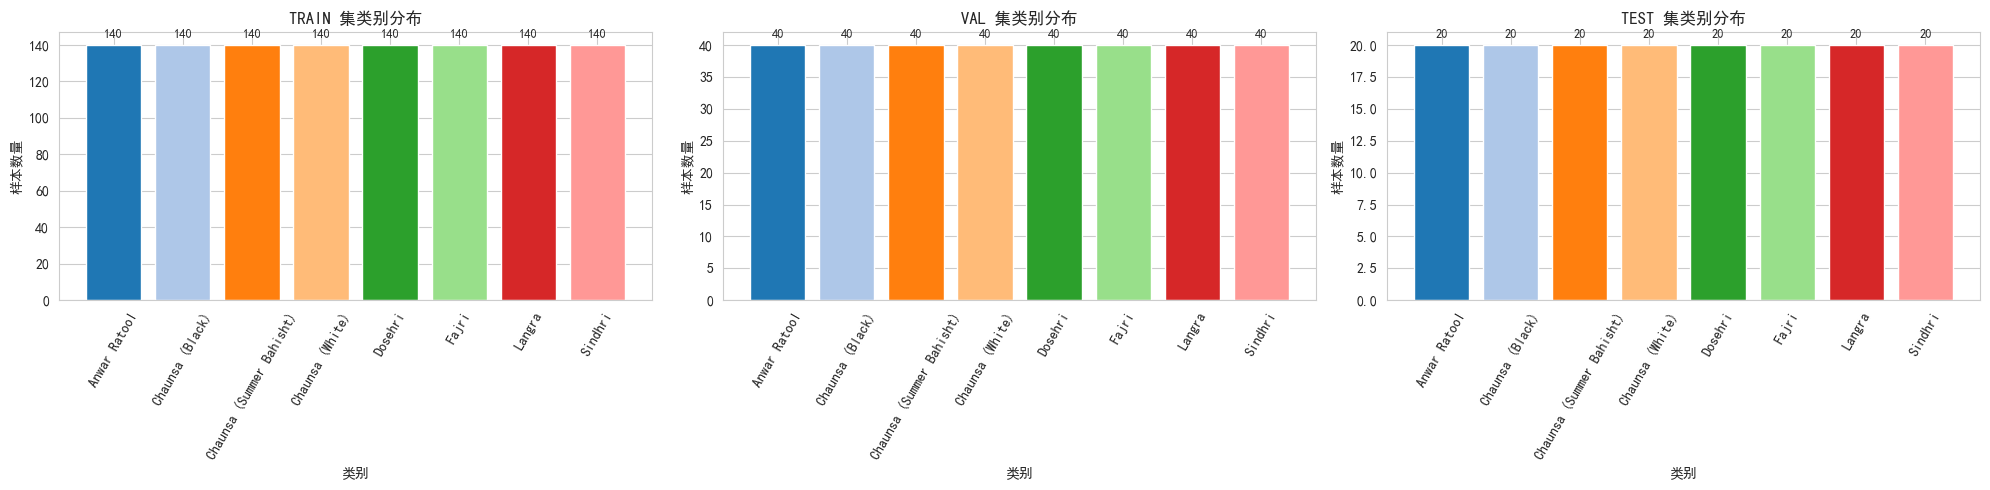

In [3]:
# 数据集统计分析
print('=' * 60)
print('数据集详细统计')
print('=' * 60)

for split in ['train', 'val', 'test']:
    print(f'\n【{split.upper()}】集合:')
    targets = image_datasets[split].targets
    for class_name, class_idx in class_to_idx.items():
        count = targets.count(class_idx)
        percentage = count / len(targets) * 100
        print(f'  {class_name:25s}: {count:4d} 张 ({percentage:5.2f}%)')
    print(f"  {'总计':25s}: {len(targets):4d} 张")

print('\n' + '=' * 60)
print('类别平衡性分析')
print('=' * 60)
train_counts = [image_datasets['train'].targets.count(i) for i in range(len(class_names))]
max_count = max(train_counts)
min_count = min(train_counts)
imbalance_ratio = max_count / min_count
print(f'最大类别样本数: {max_count}')
print(f'最小类别样本数: {min_count}')
print(f'不平衡比例: {imbalance_ratio:.2f}:1')
print('⚠️  数据集存在较严重的类别不平衡！' if imbalance_ratio > 3 else '✓ 数据集类别分布相对均衡')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
colors = plt.cm.tab20.colors[:len(class_names)]
for idx, split in enumerate(['train', 'val', 'test']):
    targets = image_datasets[split].targets
    class_counts = [targets.count(i) for i in range(len(class_names))]
    axes[idx].bar(class_names, class_counts, color=colors)
    axes[idx].set_title(f'{split.upper()} 集类别分布', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('类别')
    axes[idx].set_ylabel('样本数量')
    axes[idx].tick_params(axis='x', rotation=60)
    for i, count in enumerate(class_counts):
        axes[idx].text(i, count + max(class_counts) * 0.02, str(count), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 3. 训练样本展示

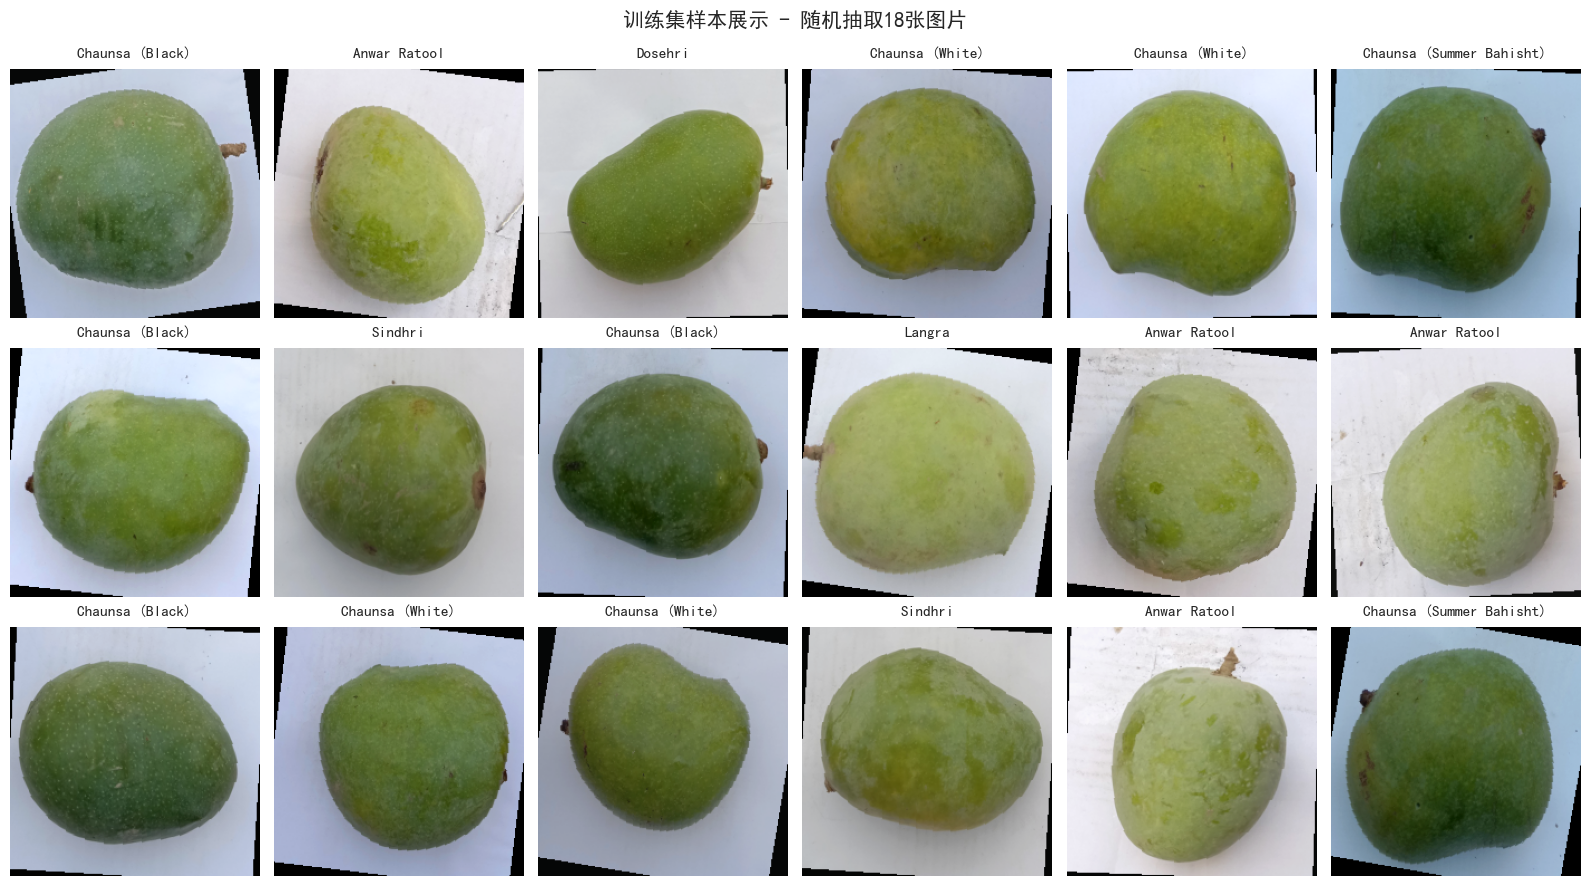

In [4]:
# 展示部分训练样本
fig, axes = plt.subplots(3, 6, figsize=(16, 9))
axes = axes.flatten()
sample_indices = random.sample(range(len(image_datasets['train'])), min(18, len(image_datasets['train'])))

# 用于反归一化的均值和标准差
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for idx, sample_idx in enumerate(sample_indices):
    img, label = image_datasets['train'][sample_idx]
    # 反归一化
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    axes[idx].imshow(img)
    axes[idx].set_title(class_names[label], fontsize=11, pad=8)
    axes[idx].axis('off')

plt.suptitle('训练集样本展示 - 随机抽取18张图片', fontsize=15, y=0.99, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. EfficientNet-B4 芒果品种分类模型与类别权重

In [5]:
from torchvision import models

# 不使用 ImageNet 预训练权重，从零开始训练 EfficientNet-B4。
base_model = models.efficientnet_b4(weights=None)
num_features = base_model.classifier[1].in_features
base_model.classifier = nn.Sequential(nn.Dropout(0.35), nn.Linear(num_features, len(class_names)))
model = base_model.to(DEVICE)

train_targets = torch.tensor(image_datasets['train'].targets)
counts = torch.bincount(train_targets, minlength=len(class_names)).float()
if torch.any(counts == 0):
    raise ValueError('At least one class has no training images.')
class_weights = (counts.sum() / (len(class_names) * counts)).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
print('Train class counts:', counts.int().tolist())
print('Class weights:', class_weights.cpu().tolist())
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

Train class counts: [140, 140, 140, 140, 140, 140, 140, 140]
Class weights: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Parameters: 17,562,960


## 5. 训练循环（早停与模型保存）

In [6]:
# 使用训练集类别频次计算的加权交叉熵损失。
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# 兼容 PyTorch 2.0.x；新版本也可继续使用 torch.cuda.amp API。
use_amp = DEVICE.type == 'cuda' and hasattr(torch.cuda, 'amp')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp) if use_amp else None

best_val_loss = float('inf')
best_val_acc = 0.0
best_state = None
bad_epochs = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}
checkpoint_path = MODEL_DIR / 'mango_variety_best_checkpoint.pth'

print(f'开始训练 - 总共 {NUM_EPOCHS} 轮')
print(f'初始学习率: {LEARNING_RATE}')
print(f'早停耐心值: {PATIENCE} 轮')
print(f'混合精度训练: {"启用" if use_amp else "关闭"}')
print('-' * 60)

for epoch in range(NUM_EPOCHS):
    print(f'\n{"=" * 60}')
    print(f'Epoch {epoch + 1}/{NUM_EPOCHS}')
    print(f'{"=" * 60}')
    current_lr = optimizer.param_groups[0]['lr']
    history['lr'].append(current_lr)
    print(f'当前学习率: {current_lr:.6f}')

    for phase in ('train', 'val'):
        model.train() if phase == 'train' else model.eval()
        running_loss = 0.0
        running_corrects = 0
        total_samples = 0
        phase_desc = '训练' if phase == 'train' else '验证'

        for inputs, labels in tqdm(loaders[phase], desc='训练' if phase == 'train' else '验证', leave=False, dynamic_ncols=True):
            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            batch_size = labels.size(0)
            if phase == 'train':
                optimizer.zero_grad(set_to_none=True)

            with torch.set_grad_enabled(phase == 'train'):
                if use_amp:
                    with torch.cuda.amp.autocast():
                        logits = model(inputs)
                        loss = criterion(logits, labels)
                else:
                    logits = model(inputs)
                    loss = criterion(logits, labels)
                preds = logits.argmax(dim=1)

                if phase == 'train':
                    if use_amp:
                        scaler.scale(loss).backward()
                        scaler.unscale_(optimizer)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        scaler.step(optimizer)
                        scaler.update()
                    else:
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        optimizer.step()

            running_loss += loss.item() * batch_size
            running_corrects += (preds == labels).sum().item()
            total_samples += batch_size

        epoch_loss = running_loss / total_samples
        epoch_acc = running_corrects / total_samples
        history[f'{phase}_loss'].append(epoch_loss)
        history[f'{phase}_acc'].append(epoch_acc)
        print(f'{phase_desc}结果 - Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f} ({running_corrects}/{total_samples})')

        if phase == 'val':
            scheduler.step(epoch_loss)
            if epoch_loss < best_val_loss:
                print(f'✓ 验证损失改善: {best_val_loss:.4f} -> {epoch_loss:.4f}')
                best_val_loss = epoch_loss
                best_val_acc = epoch_acc
                best_state = copy.deepcopy(model.state_dict())
                torch.save({'epoch': epoch + 1, 'model_state_dict': best_state,
                            'optimizer_state_dict': optimizer.state_dict(),
                            'val_loss': best_val_loss, 'val_acc': best_val_acc}, checkpoint_path)
                bad_epochs = 0
                print(f'✓ 已保存最佳模型检查点: {checkpoint_path}')
            else:
                bad_epochs += 1
                print(f'✗ 验证损失未改善 ({bad_epochs}/{PATIENCE})')

    if bad_epochs >= PATIENCE:
        print(f'\n早停触发！验证损失连续 {PATIENCE} 轮未改善')
        break

if best_state is None:
    raise RuntimeError('训练过程中未产生有效的验证检查点')
checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
print(f'\n已加载最佳模型 (Epoch {checkpoint["epoch"]})')
print(f'最佳验证损失: {checkpoint["val_loss"]:.4f}')
print(f'最佳验证准确率: {checkpoint["val_acc"]:.4f}')

final_model = MODEL_DIR / 'mango_variety_model.pth'
torch.save(model.state_dict(), final_model)
print(f'最终模型已保存至: {final_model}')

history_path = RUNS_DIR / 'mango_variety_training_history.csv'
with history_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'learning_rate'])
    for i, values in enumerate(zip(history['train_loss'], history['train_acc'], history['val_loss'], history['val_acc'], history['lr']), 1):
        writer.writerow([i, *values])
classes_path = RUNS_DIR / 'mango_variety_classes.json'
with classes_path.open('w', encoding='utf-8') as f:
    json.dump(class_to_idx, f, ensure_ascii=False, indent=2)
print(f'训练历史和类别映射已保存至: {RUNS_DIR}')

开始训练 - 总共 100 轮
初始学习率: 0.0001
早停耐心值: 10 轮
混合精度训练: 启用
------------------------------------------------------------

Epoch 1/100
当前学习率: 0.000100


训练结果 - Loss: 2.0877, Accuracy: 0.1652 (185/1120)


验证结果 - Loss: 2.0881, Accuracy: 0.1250 (40/320)
✓ 验证损失改善: inf -> 2.0881
✓ 已保存最佳模型检查点: D:\WorkSpace2\plants-intelligent-system\models\mango_variety_best_checkpoint.pth

Epoch 2/100
当前学习率: 0.000100


训练结果 - Loss: 2.0745, Accuracy: 0.1777 (199/1120)


验证结果 - Loss: 2.0994, Accuracy: 0.1250 (40/320)
✗ 验证损失未改善 (1/10)

Epoch 3/100
当前学习率: 0.000100


训练结果 - Loss: 1.9512, Accuracy: 0.2509 (281/1120)


... (111 outputs left out)

训练结果 - Loss: 0.0898, Accuracy: 0.9732 (1090/1120)


验证结果 - Loss: 0.0054, Accuracy: 0.9969 (319/320)
✗ 验证损失未改善 (9/10)

Epoch 60/100
当前学习率: 0.000002


训练结果 - Loss: 0.0726, Accuracy: 0.9759 (1093/1120)


验证结果 - Loss: 0.0044, Accuracy: 1.0000 (320/320)
✗ 验证损失未改善 (10/10)

早停触发！验证损失连续 10 轮未改善

已加载最佳模型 (Epoch 50)
最佳验证损失: 0.0037
最佳验证准确率: 1.0000
最终模型已保存至: D:\WorkSpace2\plants-intelligent-system\models\mango_variety_model.pth
训练历史和类别映射已保存至: D:\WorkSpace2\plants-intelligent-system\train\runs


## 6. 训练历史可视化

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

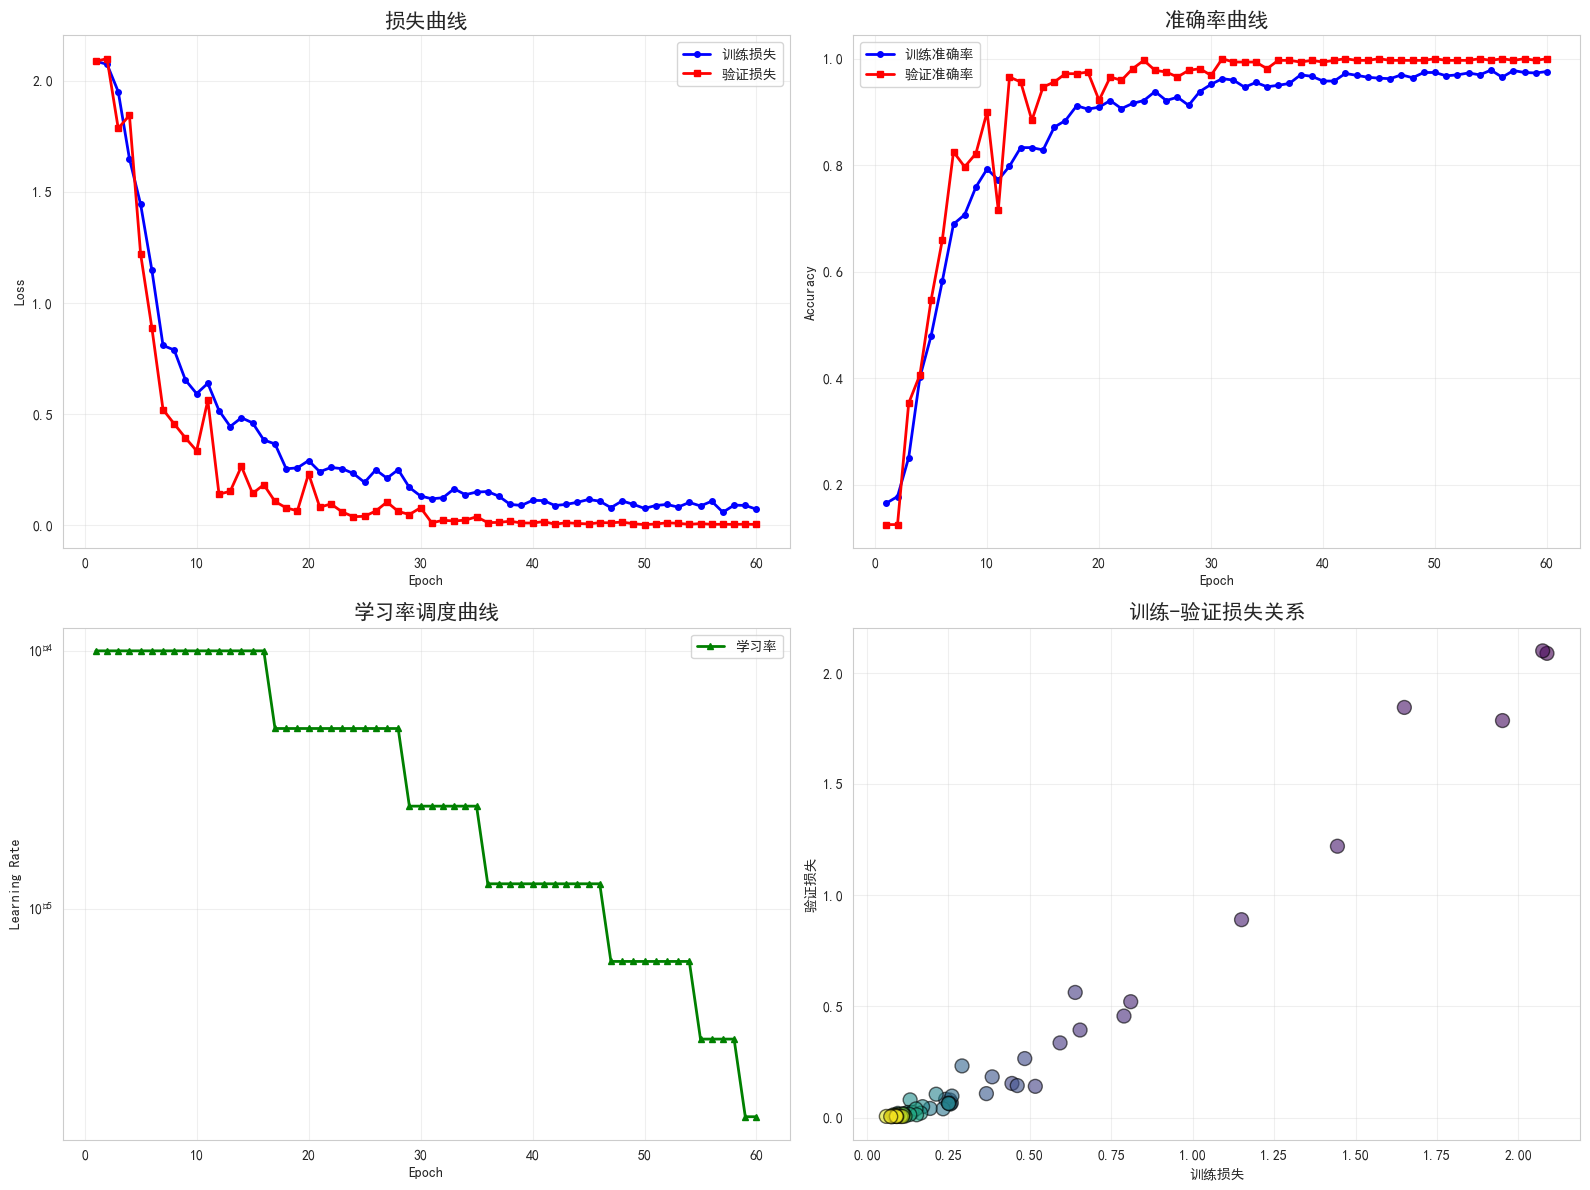

训练曲线已保存至: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_variety_training_curves.png


In [7]:
# 绘制训练历史曲线
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
epochs_range = range(1, len(history['train_loss']) + 1)
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-o', label='训练损失', linewidth=2, markersize=4)
axes[0, 0].plot(epochs_range, history['val_loss'], 'r-s', label='验证损失', linewidth=2, markersize=4)
axes[0, 0].set_title('损失曲线', fontsize=15, fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)
axes[0, 1].plot(epochs_range, history['train_acc'], 'b-o', label='训练准确率', linewidth=2, markersize=4)
axes[0, 1].plot(epochs_range, history['val_acc'], 'r-s', label='验证准确率', linewidth=2, markersize=4)
axes[0, 1].set_title('准确率曲线', fontsize=15, fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Accuracy'); axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)
axes[1, 0].plot(epochs_range, history['lr'], 'g-^', label='学习率', linewidth=2, markersize=5)
axes[1, 0].set_title('学习率调度曲线', fontsize=15, fontweight='bold')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Learning Rate'); axes[1, 0].set_yscale('log'); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)
axes[1, 1].scatter(history['train_loss'], history['val_loss'], c=range(len(history['train_loss'])), cmap='viridis', s=100, alpha=0.6, edgecolors='black')
axes[1, 1].set_title('训练-验证损失关系', fontsize=15, fontweight='bold')
axes[1, 1].set_xlabel('训练损失'); axes[1, 1].set_ylabel('验证损失'); axes[1, 1].grid(alpha=0.3)
plt.tight_layout()
curve_path = RUNS_DIR / 'mango_variety_training_curves.png'
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'训练曲线已保存至: {curve_path}')

## 7. 测试集最终评估

Test accuracy: 1.0000
                          precision    recall  f1-score   support

            Anwar Ratool     1.0000    1.0000    1.0000        20
         Chaunsa (Black)     1.0000    1.0000    1.0000        20
Chaunsa (Summer Bahisht)     1.0000    1.0000    1.0000        20
         Chaunsa (White)     1.0000    1.0000    1.0000        20
                 Dosehri     1.0000    1.0000    1.0000        20
                   Fajri     1.0000    1.0000    1.0000        20
                  Langra     1.0000    1.0000    1.0000        20
                 Sindhri     1.0000    1.0000    1.0000        20

                accuracy                         1.0000       160
               macro avg     1.0000    1.0000    1.0000       160
            weighted avg     1.0000    1.0000    1.0000       160


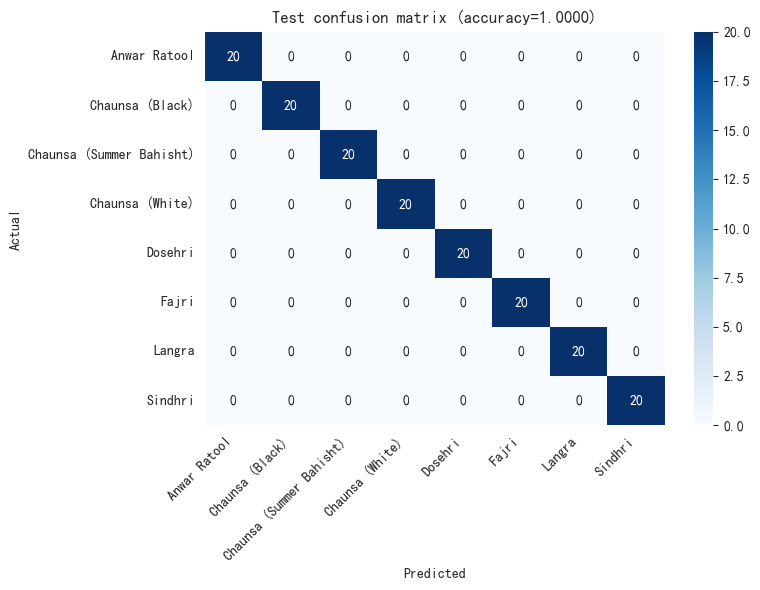

Test metrics saved to: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_variety_metrics.json


In [8]:
# The test set is used once, after selecting the checkpoint with validation loss.
model.eval()
y_true, y_pred = [], []
with torch.inference_mode():
    for inputs, labels in tqdm(loaders['test'], desc='测试', leave=False, dynamic_ncols=True):
        logits = model(inputs.to(DEVICE, non_blocking=True))
        y_pred.extend(logits.argmax(1).cpu().tolist())
        y_true.extend(labels.tolist())

test_accuracy = float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
label_ids = list(range(len(class_names)))
cm = confusion_matrix(y_true, y_pred, labels=label_ids)
print(f'Test accuracy: {test_accuracy:.4f}')
print(classification_report(y_true, y_pred, labels=label_ids, target_names=class_names, zero_division=0, digits=4))
plt.figure(figsize=(max(8, len(class_names)), max(6, len(class_names) * 0.75)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'Test confusion matrix (accuracy={test_accuracy:.4f})')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
confusion_path = RUNS_DIR / 'mango_variety_confusion_matrix.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()
metrics_path = RUNS_DIR / 'mango_variety_metrics.json'
with metrics_path.open('w', encoding='utf-8') as f:
    json.dump({'test_accuracy': test_accuracy, 'best_val_loss': best_val_loss, 'class_to_idx': class_to_idx}, f, ensure_ascii=False, indent=2)
print(f'Test metrics saved to: {metrics_path}')